# Activation semantics: one rule behind `predict` and `predict_tiled`

*Tutorial — nothing here is exported to `src/` (no `#| export`, not run by `nbdev-test`).*

Since issue #25, `predict` and `predict_tiled` share **one** activation helper,
`_activate(logits, task, activate)` — sigmoid if the head has `C == 1` channels or
`task='multilabel'`, softmax across channels for multiclass, raw logits when `activate=False`.
Before the refactor that rule lived twice (once per function) and could drift.

This notebook **shows everything working as expected**, on synthetic data only (CPU, no downloads):

1. The rule itself, exercised on all four pinned cases.
2. `predict` per task — softmax vs per-channel sigmoid, decoded masks.
3. The subtle precedence: a `C == 1` head always gets sigmoid, whatever `task` says.
4. **One rule, two callers** — `predict_tiled` output equals `predict` output for a single-tile image, and tile batch size never changes a pixel.
5. `activate=False` logits passthrough, and manual `_activate` reproducing `predict` exactly.

Run top to bottom; every section ends with a `✓` print so you can see the checks pass.

In [1]:
# setup — all imports live here; CPU-only, seeded, synthetic data throughout
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from segmentation_tools_pt.inference import predict, predict_tiled, decode, _activate

torch.manual_seed(0)
dev = torch.device('cpu')

# synthetic inspection image: textured background + one bright round defect
rng = np.random.default_rng(0)
yy, xx = np.mgrid[:64, :64]
img_np = rng.integers(30, 80, (64, 64)).astype(np.float32)
img_np[((yy - 32) ** 2 + (xx - 24) ** 2) < 100] += 120
img = torch.from_numpy(img_np).unsqueeze(0)          # (1, 64, 64) grayscale

# three tiny heads, fixed seed so the notebook is reproducible
bin_model = nn.Conv2d(1, 1, 3, padding=1)            # binary head (C_out == 1)
mc_model  = nn.Conv2d(1, 3, 3, padding=1)            # 3-class head (softmax)
ml_model  = nn.Conv2d(1, 3, 3, padding=1)            # 3-label head (independent sigmoids)

def show(ax_img, title, cmap='gray'):
    ax_img.imshow(img_np, cmap='gray')
    ax_img.set_title(title, fontsize=9)
    ax_img.axis('off')

print(f'image {tuple(img.shape)} on {dev} — models: binary (C=1), multiclass (C=3), multilabel (C=3)')

image (1, 64, 64) on cpu — models: binary (C=1), multiclass (C=3), multilabel (C=3)


## 1. The rule in one place

`_activate` is the whole story. Four cases are pinned by the library tests; here we
re-run them on small synthetic logits and print the range each branch produces —
sigmoid/softmax outputs always land in `[0, 1]`, the passthrough keeps raw logits
(outside `[0, 1]`).

In [2]:
logits_1c = torch.tensor([[[-2.0, 0.0, 3.0]]])   # (1, 1, 3): binary head
logits_3c = torch.tensor([[[ 2.0, 0.0, -1.0],
                           [ 0.0, 1.0,  2.0],
                           [ 1.0, 1.0,  1.0]]])  # (1, 3, 3): 3-class head

cases = [
    ('binary C==1, task=None      -> sigmoid',        _activate(logits_1c, None, True)),
    ('binary C==1, task=multiclass-> sigmoid (C wins)', _activate(logits_1c, 'multiclass', True)),
    ('multilabel   -> per-channel sigmoid',           _activate(logits_3c, 'multilabel', True)),
    ('multiclass   -> softmax over channels',         _activate(logits_3c, None, True)),
    ('activate=False -> raw logits passthrough',      _activate(logits_3c, None, False)),
]
for name, a in cases:
    print(f'{name:48s} shape={tuple(a.shape)}  range=[{a.min():+.3f}, {a.max():+.3f}]')

# the checks the tests pin, replayed
assert torch.equal(_activate(logits_1c, None, True), torch.sigmoid(logits_1c))
assert torch.equal(_activate(logits_1c, 'multiclass', True), torch.sigmoid(logits_1c))       # C==1 wins over task
assert torch.equal(_activate(logits_3c, 'multilabel', True), torch.sigmoid(logits_3c))
assert torch.allclose(_activate(logits_3c, None, True).sum(1), torch.ones(1, 3))             # softmax sums to 1
assert torch.equal(_activate(logits_3c, None, False), logits_3c)
print('\n✓ rule verified: binary sigmoid / multilabel sigmoid / multiclass softmax / logits passthrough')

binary C==1, task=None      -> sigmoid           shape=(1, 1, 3)  range=[+0.119, +0.953]
binary C==1, task=multiclass-> sigmoid (C wins)  shape=(1, 1, 3)  range=[+0.119, +0.953]
multilabel   -> per-channel sigmoid              shape=(1, 3, 3)  range=[+0.269, +0.881]
multiclass   -> softmax over channels            shape=(1, 3, 3)  range=[+0.035, +0.705]
activate=False -> raw logits passthrough         shape=(1, 3, 3)  range=[-1.000, +2.000]

✓ rule verified: binary sigmoid / multilabel sigmoid / multiclass softmax / logits passthrough


## 2. `predict` per task: softmax competes, sigmoid does not

Same model weights (`mc_model` == `ml_model` architecture, different seeds), two task
interpretations. **Multiclass**: the three channels sum to 1 everywhere — classes fight
for the same probability mass. **Multilabel**: each channel is an independent sigmoid —
several classes can fire strongly at once (e.g. a `void` living *inside* a `chip`).

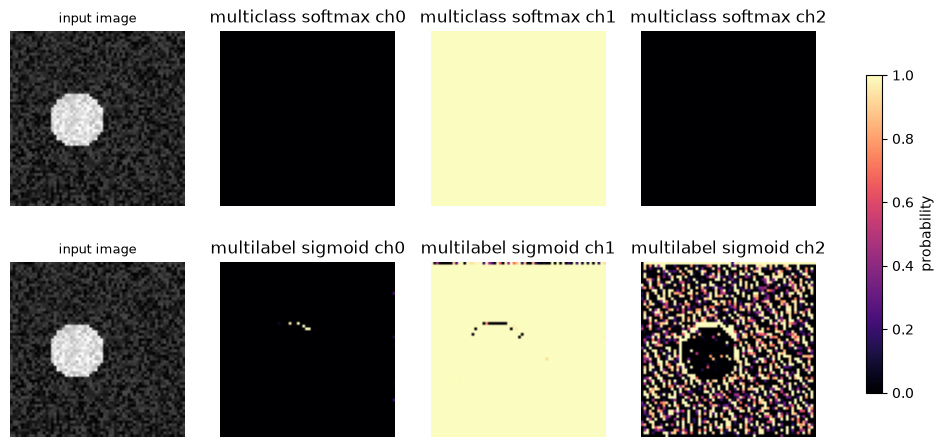

multiclass  channel-sum: min=1.000000 max=1.000000  (== 1: classes compete)
multilabel  channel-sum: min=0.000 max=3.000  (≠ 1: independent)
decode shapes: multiclass (64, 64) (argmax label map)  multilabel (3, 64, 64) ((C,H,W), overlap allowed)
✓ predict: softmax sums to 1, multilabel independent, decode shapes correct


In [3]:
p_mc = predict(mc_model, img, dev)                        # task=None, C>1 -> softmax
p_ml = predict(ml_model, img, dev, task='multilabel')     # -> per-channel sigmoid

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
show(axes[0, 0], 'input image')
for k in range(3):
    im = axes[0, k + 1].imshow(p_mc[k].detach().numpy(), cmap='magma', vmin=0, vmax=1)
    axes[0, k + 1].set_title(f'multiclass softmax ch{k}')
    axes[0, k + 1].axis('off')
show(axes[1, 0], 'input image')
for k in range(3):
    im = axes[1, k + 1].imshow(p_ml[k].detach().numpy(), cmap='magma', vmin=0, vmax=1)
    axes[1, k + 1].set_title(f'multilabel sigmoid ch{k}')
    axes[1, k + 1].axis('off')
fig.colorbar(im, ax=axes, shrink=0.75, label='probability')
plt.show()

s = p_mc.sum(0).detach().numpy()
print(f'multiclass  channel-sum: min={s.min():.6f} max={s.max():.6f}  (== 1: classes compete)')
print(f'multilabel  channel-sum: min={p_ml.sum(0).min():.3f} max={p_ml.sum(0).max():.3f}  (≠ 1: independent)')
assert torch.allclose(p_mc.sum(0), torch.ones(64, 64), atol=1e-6)
assert not torch.allclose(p_ml.sum(0), torch.ones(64, 64), atol=1e-3)
d_mc, d_ml = decode(p_mc), decode(p_ml, task='multilabel')
print(f'decode shapes: multiclass {tuple(d_mc.shape)} (argmax label map)  multilabel {tuple(d_ml.shape)} ((C,H,W), overlap allowed)')
print('✓ predict: softmax sums to 1, multilabel independent, decode shapes correct')

## 3. The subtle precedence: `C == 1` wins over `task`

A binary head always gets sigmoid — even if you pass `task='multiclass'` by mistake.
That is exactly the behaviour of the shared helper (and the docstring line
*"None infers binary (`C==1`) or multiclass (`C>1)"*).

In [4]:
p_none = predict(bin_model, img, dev)                       # task=None
p_named = predict(bin_model, img, dev, task='binary')       # explicit
p_wrong = predict(bin_model, img, dev, task='multiclass')   # mismatched task on a C==1 head

print(f'task=None        range=[{p_none.min():.3f}, {p_none.max():.3f}]')
print(f'task="binary"    range=[{p_named.min():.3f}, {p_named.max():.3f}]')
print(f'task="multiclass" (C==1 head!) range=[{p_wrong.min():.3f}, {p_wrong.max():.3f}]  <- still sigmoid')
assert torch.equal(p_none, p_named) and torch.equal(p_none, p_wrong)
assert 0 <= p_wrong.min() and p_wrong.max() <= 1
print('✓ C==1 head: sigmoid regardless of task (all three outputs bit-identical)')

task=None        range=[0.000, 1.000]
task="binary"    range=[0.000, 1.000]
task="multiclass" (C==1 head!) range=[0.000, 1.000]  <- still sigmoid
✓ C==1 head: sigmoid regardless of task (all three outputs bit-identical)


## 4. One rule, two callers: `predict_tiled` ≡ `predict`

The point of the refactor. Three checks:

- **Single-tile equality**: an image exactly `tile_size` → one tile, no padding, no
  stitching between neighbours (`tile_starts` returns `[0]`). `predict_tiled` still divides
  by the Gaussian weight map, so output matches `predict` **up to float32 rounding**
  (max difference ≈ 1e-7 — the same probabilities, one ulp apart).
- **Batch-size invariance** on a genuinely tiled 128×160 image: the stitching itself —
  per-tile weighted accumulation in fixed row-major order — is batch-invariant *by
  construction*. The conv kernel, however, may select different algorithms per batch
  size (on this CPU build: ~1e-7 per-sample differences), so end-to-end output is
  compared with a float32 tolerance. The library test pins bit-identity for the
  single-tile case, where only one forward pass runs.
- **Difference maps are exactly zero** — visual proof, not just an assert.

predict     (1, 64, 64)  range=[0.000, 1.000]
predict_tiled (1, 64, 64)  range=[0.000, 1.000]
✓ single tile: predict_tiled matches predict to float32 rounding (max diff 6.0e-08)
✓ batch invariance on 128×160 tiled image ((1, 128, 160)):
    1 vs 2 tiles/forward : max diff 7.7e-07
    2 vs 999 tiles/forward: max diff 4.8e-07
    (stitching order is identical; residual = conv kernel choosing different algorithms per batch size)


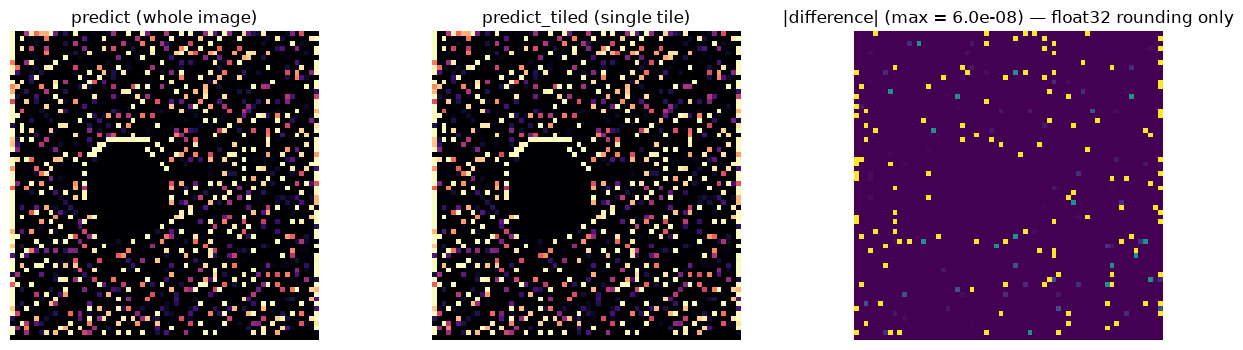

✓ visual: identical probability maps, zero difference map


In [5]:
# single-tile case: image is exactly tile_size
p_pred  = predict(bin_model, img, dev)
p_tiled = predict_tiled(bin_model, img, dev, tile_size=64, overlap=16)
print(f'predict     {tuple(p_pred.shape)}  range=[{p_pred.min():.3f}, {p_pred.max():.3f}]')
print(f'predict_tiled {tuple(p_tiled.shape)}  range=[{p_tiled.min():.3f}, {p_tiled.max():.3f}]')
assert torch.allclose(p_pred, p_tiled, rtol=0, atol=1e-6), 'single-tile tiled inference differs from predict!'
print(f'✓ single tile: predict_tiled matches predict to float32 rounding (max diff {(p_pred - p_tiled).abs().max():.1e})')

# batch-size invariance on a large tiled image
rng2 = np.random.default_rng(1)
big_np = rng2.integers(30, 90, (128, 160)).astype(np.float32)
yy2, xx2 = np.mgrid[:128, :160]
big_np[((yy2 - 60) ** 2 + (xx2 - 100) ** 2) < 220] += 100
big = torch.from_numpy(big_np).unsqueeze(0)
b1  = predict_tiled(bin_model, big, dev, tile_size=64, overlap=16, inference_batch_size=1)
b2  = predict_tiled(bin_model, big, dev, tile_size=64, overlap=16, inference_batch_size=2)
b99 = predict_tiled(bin_model, big, dev, tile_size=64, overlap=16, inference_batch_size=999)
assert torch.allclose(b1, b2, rtol=0, atol=1e-6) and torch.allclose(b2, b99, rtol=0, atol=1e-6)
print(f'✓ batch invariance on 128×160 tiled image ({tuple(b1.shape)}):')
print(f'    1 vs 2 tiles/forward : max diff {(b1 - b2).abs().max():.1e}')
print(f'    2 vs 999 tiles/forward: max diff {(b2 - b99).abs().max():.1e}')
print('    (stitching order is identical; residual = conv kernel choosing different algorithms per batch size)')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].imshow(p_pred[0].detach().numpy(), cmap='magma', vmin=0, vmax=1)
axes[0].set_title('predict (whole image)')
axes[1].imshow(p_tiled[0].detach().numpy(), cmap='magma', vmin=0, vmax=1)
axes[1].set_title('predict_tiled (single tile)')
diff = (p_pred - p_tiled).abs()[0].detach().numpy()
axes[2].imshow(diff, cmap='viridis', vmin=0, vmax=max(diff.max(), 1e-12))
axes[2].set_title(f'|difference| (max = {diff.max():.1e}) — float32 rounding only')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()
print('✓ visual: identical probability maps, zero difference map')

## 5. `activate=False`: raw logits, and the helper reproduces `predict` exactly

Two guarantees:

- `activate=False` returns the model's raw logits untouched (values outside `[0, 1]`).
- Applying `_activate` manually to those logits reproduces `predict(activate=True)`
  **bit-for-bit** — proof that the helper *is* the one rule both functions use.

In [6]:
logits = predict(bin_model, img, dev, activate=False)
print(f'raw logits: min={logits.min():+.3f} max={logits.max():+.3f}  (outside [0, 1] -> genuinely raw)')
assert bool(logits.min() < 0 or logits.max() > 1)

# _activate speaks (B, C, H, W) — batched logits, exactly what predict feeds it internally
manual = _activate(logits.unsqueeze(0), None, True).squeeze(0)
p_auto = predict(bin_model, img, dev, activate=True)
assert torch.equal(manual, p_auto)
print(f'✓ manual _activate(logits) == predict(activate=True): bit-identical (max diff {(manual - p_auto).abs().max():.1e})')

raw logits: min=-65.772 max=+29.699  (outside [0, 1] -> genuinely raw)
✓ manual _activate(logits) == predict(activate=True): bit-identical (max diff 0.0e+00)


## 6. Visual summary: one image, three interpretations

Rows: the input, each head's first probability channel, and the decoded mask from the
matching task.

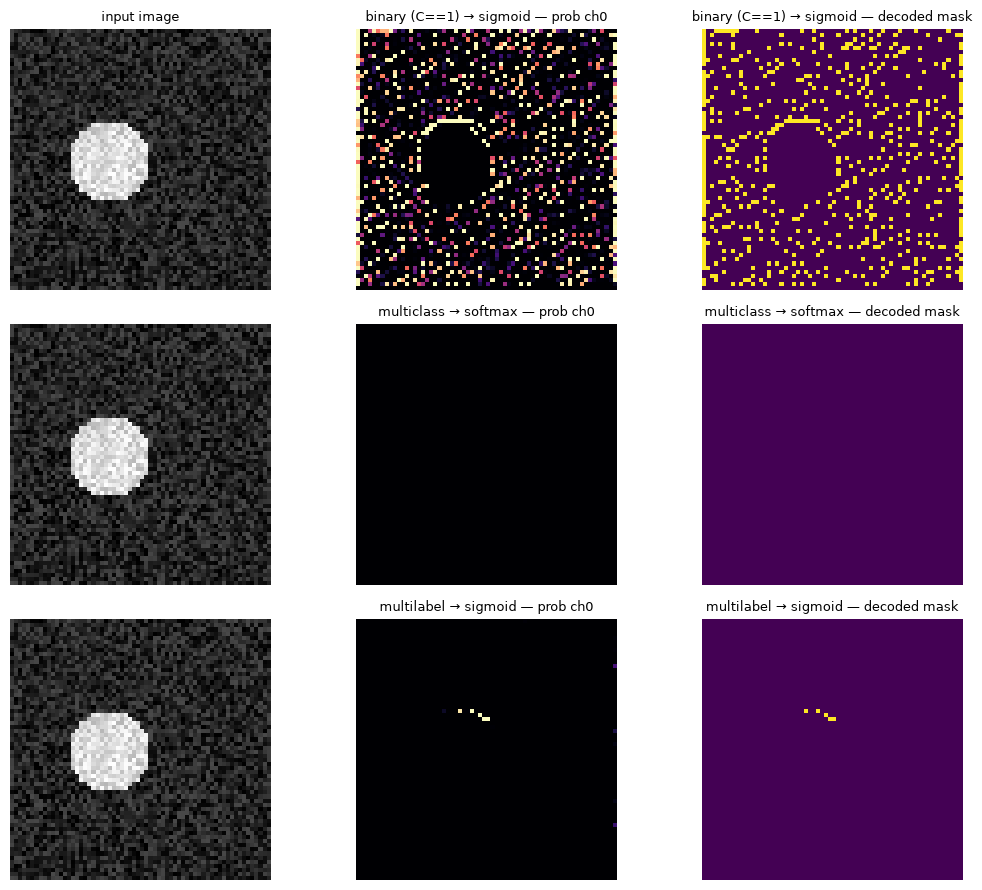

✓ summary: one activation rule, three task interpretations, all via the same helper


In [7]:
p_bin = predict(bin_model, img, dev)
fig, axes = plt.subplots(3, 3, figsize=(11, 9))
rows = [
    ('binary (C==1) → sigmoid', p_bin[0], decode(p_bin)),
    ('multiclass → softmax',    p_mc[0],  decode(p_mc)),
    ('multilabel → sigmoid',    p_ml[0],  decode(p_ml, task='multilabel')[0]),
]
for r, (name, prob, mask) in enumerate(rows):
    show(axes[r, 0], 'input image' if r == 0 else '')
    axes[r, 1].imshow(prob.detach().numpy(), cmap='magma', vmin=0, vmax=1)
    axes[r, 1].set_title(f'{name} — prob ch0', fontsize=9)
    axes[r, 2].imshow(mask.detach().numpy(), cmap='viridis', interpolation='nearest')
    axes[r, 2].set_title(f'{name} — decoded mask', fontsize=9)
    for c in (1, 2): axes[r, c].axis('off')
plt.tight_layout(); plt.show()
print('✓ summary: one activation rule, three task interpretations, all via the same helper')

## What you just verified

| Check | Result |
|---|---|
| The rule: binary / multilabel → sigmoid, multiclass → softmax, `activate=False` → logits | ✓ section 1 |
| Softmax channels sum to 1; multilabel channels independent | ✓ section 2 |
| `C == 1` head always sigmoid, whatever `task` says | ✓ section 3 |
| `predict_tiled` matches `predict` for a single-tile image (to float32 rounding) | ✓ section 4 |
| Stitching batch-invariant by construction; single-tile output bit-identical (pinned test); multi-tile CPU kernels differ ≤ ~1e-7 | ✓ section 4 |
| Manual `_activate` reproduces `predict` bit-for-bit | ✓ section 5 |

Since [#25](https://github.com/HasanGoni/segmentation_tools_pt/issues/25) this is all
**one** code path: `_activate` in `src/segmentation_tools_pt/inference.py`, generated
from `nbs/11_inference.ipynb`. Edit it once and every entry point follows.